# Introduction and Research Question

Credit-card delinquency is an important indicator of household financial distress and broader economic conditions. When consumers struggle to make their credit-card payments, it may reflect financial pressures such as unemployment, inflation, or changes in economic growth. Understanding how delinquency rates relate to these indicators can help identify economic conditions associated with increased financial vulnerability. Examining these relationships is 
particularly relevant during recessions, when households may face greater uncertainty and reduced financial stability.

This report explores historical trends in credit-card delinquency rates in relation to several economic indicators on a quarterly basis over a 35 year period, including unemployment, inflation, Treasury yields, stock-market performance, personal consumption expenditures, and real gross domestic product growth. It also compares delinquency rates during recessionary and non-recessionary periods. Using exploratory data analysis (EDA), the report examines descriptive statistics, trends over time, distributions, and correlations to identify patterns and potential relationships among the variables.

### Research Question: How are credit-card delinquency rates associated with key economic indicators, and how do delinquency rates differ between recessionary and non-recessionary periods? #

The analysis aims to identify meaningful patterns in the data and assess which economic indicators appear most closely associated with credit-card 
delinquency. Because this is an exploratory analysis, the findings describe associations rather than establish causal relationships.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates

df=pd.read_csv("Data For Project - DRCCLACBS.csv")
df.head()

,observation_date,DRCCLACBS,DGS10,HOUST,UNRATE,CPIAUCSL_PC1,PCEPI_PC1,A191RL1Q225SBEA,NASDAQCOM,Recession
0,1991-01-01,5.26,8.02,895,6.6,5.25905,4.08680,-1.9,427.508,1
1,1991-04-01,5.48,8.13,1011,6.8,4.84661,3.71294,3.2,492.610,0
2,1991-07-01,5.35,7.95,1042,6.9,3.85200,3.10773,2.0,507.325,0
3,1991-10-01,5.32,7.35,1087,7.1,2.96536,2.49995,1.4,536.298,0
4,1992-01-01,5.27,7.31,1241,7.4,2.89389,2.60231,4.9,622.004,0


In [2]:
print("Dataset dimensions:", df.shape)
print("Date range:")
print(df["observation_date"].min(), "to", df["observation_date"].max())

Dataset dimensions: (141, 10)
Date range:
1991-01-01 to 2026-01-01


I've decided to add a variable that measures the change in the NASDAQ Composite between quarters because I want to see if the different changes have any effect rather than the index just gradually rises over time.

In [3]:
df["NASDAQCOM_shift"]=df["NASDAQCOM"].shift(1)
df.head()
df["NASDAQ_change"]=(df["NASDAQCOM"]-df["NASDAQCOM_shift"])

In [4]:
variables=["observation_date", "DRCCLACBS", "DGS10", "HOUST", "UNRATE", "CPIAUCSL_PC1", "PCEPI_PC1", "A191RL1Q225SBEA", "NASDAQCOM", "NASDAQ_change", "Recession"]
print("\nMissing observations by variable:")
missing_summary = pd.DataFrame({
    "Missing_Count": df[variables].isna().sum(),
    "Missing_Percent": df[variables].isna().mean() * 100
})

print(missing_summary.round(2))


print("\nDuplicate dates:", df.index.duplicated().sum())


Missing observations by variable:
                  Missing_Count  Missing_Percent
observation_date              0             0.00
DRCCLACBS                     0             0.00
DGS10                         0             0.00
HOUST                         0             0.00
UNRATE                        0             0.00
CPIAUCSL_PC1                  0             0.00
PCEPI_PC1                     0             0.00
A191RL1Q225SBEA               0             0.00
NASDAQCOM                     0             0.00
NASDAQ_change                 1             0.71
Recession                     0             0.00

Duplicate dates: 0


I have data for every single variable for every single date except for change. This is because I don't have data for the first observation at the beginning of 1991.

# Distributions of Variables

In [5]:
df[["DRCCLACBS", "DGS10", "HOUST", "UNRATE", "CPIAUCSL_PC1", "PCEPI_PC1", "A191RL1Q225SBEA", "NASDAQCOM", "NASDAQ_change"]].describe()

,DRCCLACBS,DGS10,HOUST,UNRATE,CPIAUCSL_PC1,PCEPI_PC1,A191RL1Q225SBEA,NASDAQCOM,NASDAQ_change
count,141.000000,141.000000,141.000000,141.000000,141.000000,141.000000,141.000000,141.000000,140.000000
mean,3.691702,4.129149,1329.765957,5.661702,2.624845,2.188909,2.630496,4911.449894,159.972229
std,1.183795,1.812040,376.439782,1.755915,1.513248,1.255369,4.432847,5242.572423,552.603429
min,1.530000,0.650000,526.000000,3.500000,-1.606960,-1.196320,-28.000000,427.508000,-1805.380000
25%,2.540000,2.650000,1143.000000,4.300000,1.790970,1.485920,1.500000,1691.397000,-7.941250
50%,3.850000,4.160000,1388.000000,5.300000,2.608920,2.090040,2.700000,2536.130000,94.529000
75%,4.660000,5.570000,1572.000000,6.600000,3.191520,2.628180,4.000000,6095.442000,251.207250
max,6.770000,8.130000,2120.000000,13.000000,8.584980,6.908580,34.900000,23137.843000,3132.196000


Most of these variables are fairly not skewed except for the NASDAQ Composite and the changes in the NASDAQ Composite which makes it right skewed.

I think the reason why they are skewed right is because stock indexes tend to rise over time and therefore are more likely to have large gains rather than large losses.

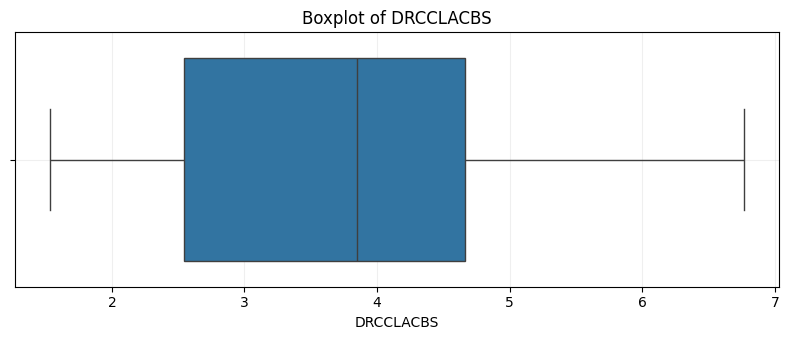

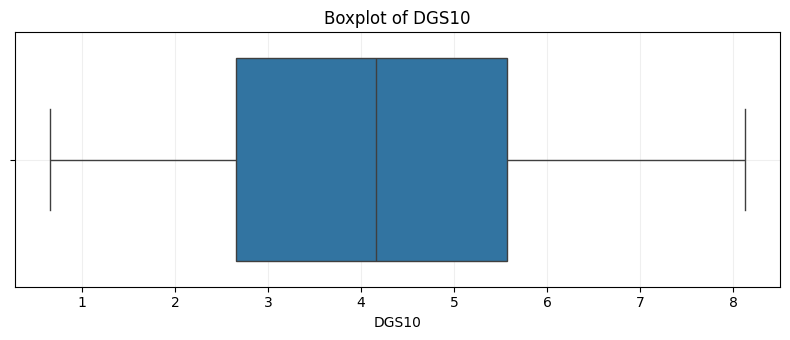

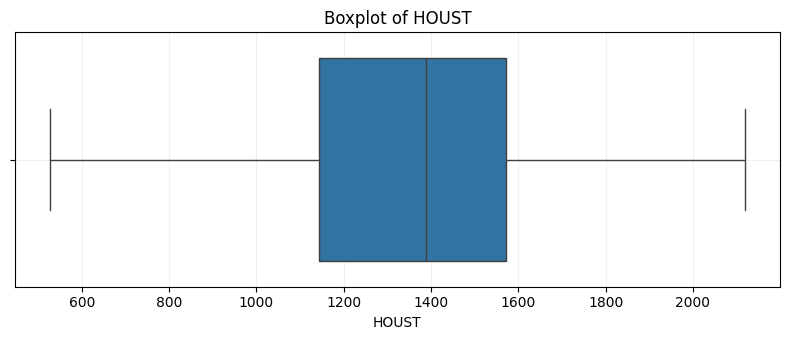

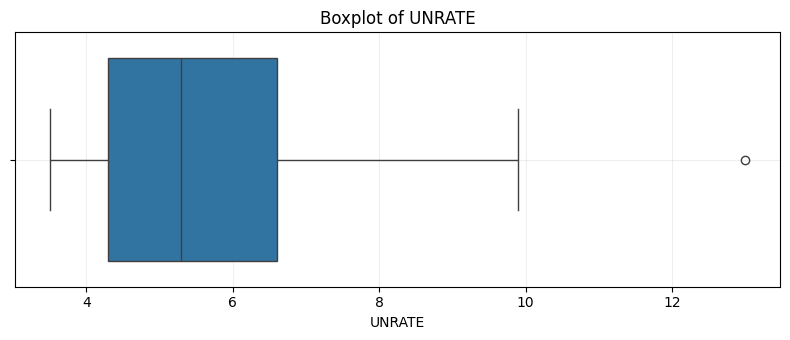

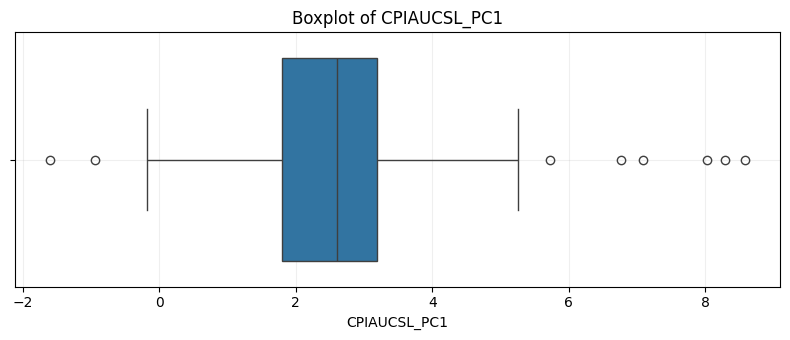

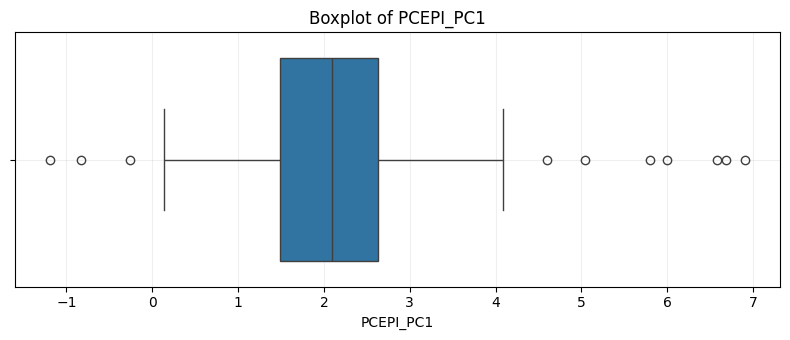

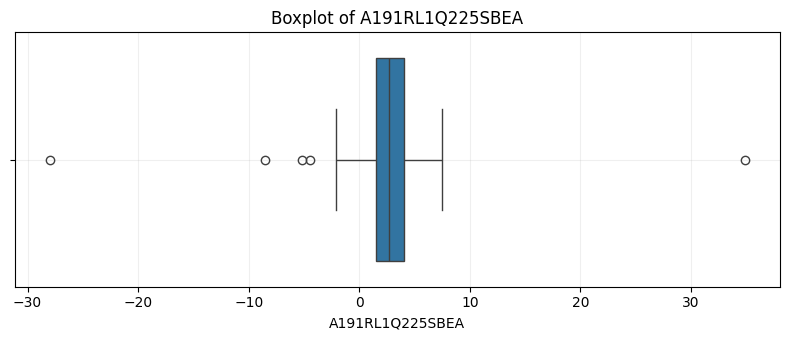

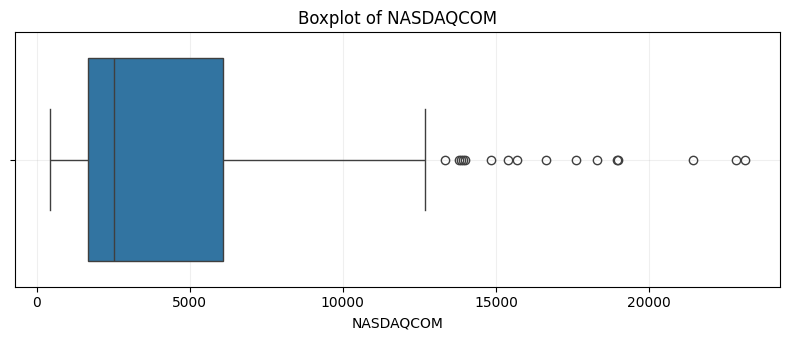

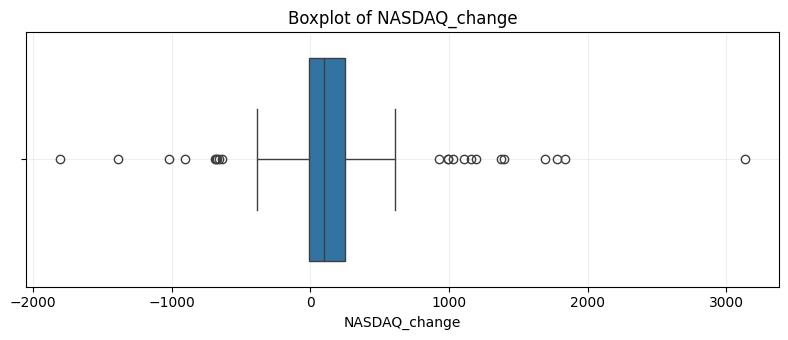

In [6]:
#vaariables.remove("NASDAQCOM")
for col in variables[1:len(variables)-1]:
    values = df[col].dropna()

    if values.empty:
        continue

    fig, ax = plt.subplots(figsize=(8, 3.5))

    sns.boxplot(x=values, ax=ax)

    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)
    ax.grid(True, alpha=0.2)

    fig.tight_layout()

I didn't include the NASDAQ Composite, because using a box plot for something that rises over time seems inappropriate.

All of the variables measured seem fairly balanced. However CPI, PCE, and changes in the NASDAQ have a lot of outliers. The presence of numerous outliers in the box plot suggests that the variable has observations that fall unusually far from its central distribution. These observations may reflect extreme economic conditions or a skewed distribution. 

# Variables over Time

In [7]:
def shade_recessions(ax, df, date_col="observation_date",
                     recession_col="Recession"):
    dates = pd.to_datetime(df[date_col])
    recession = df[recession_col].fillna(0).astype(int)

    # Identify consecutive recession periods
    in_recession = recession.eq(1)
    changes = in_recession.ne(in_recession.shift(fill_value=False))
    group = changes.cumsum()

    for _, period in df.groupby(group):
        idx = period.index
        if recession.loc[idx].iloc[0] == 1:
            start = dates.loc[idx].iloc[0]
            end = dates.loc[idx].iloc[-1]

            ax.axvspan(
                start, end,
                color="gray",
                alpha=0.25,
                linewidth=0
            )

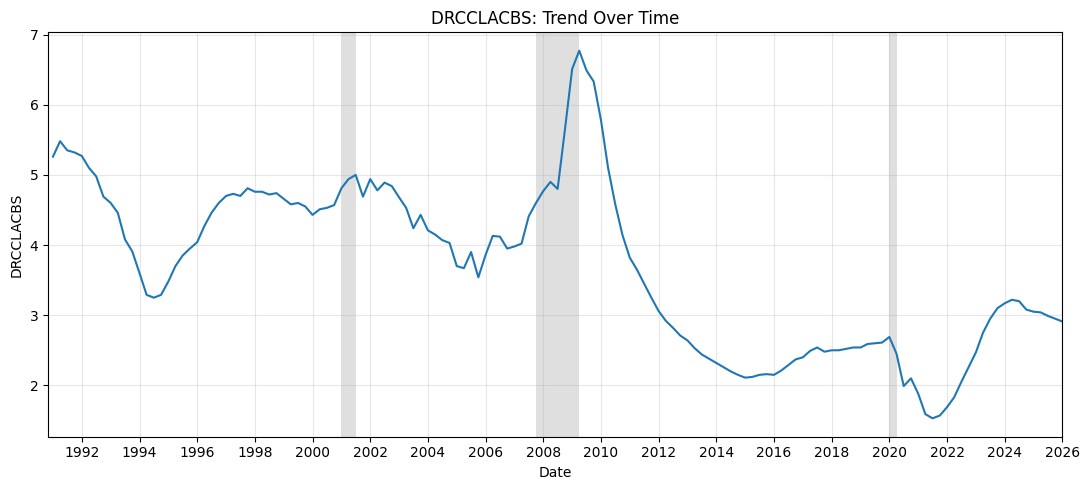

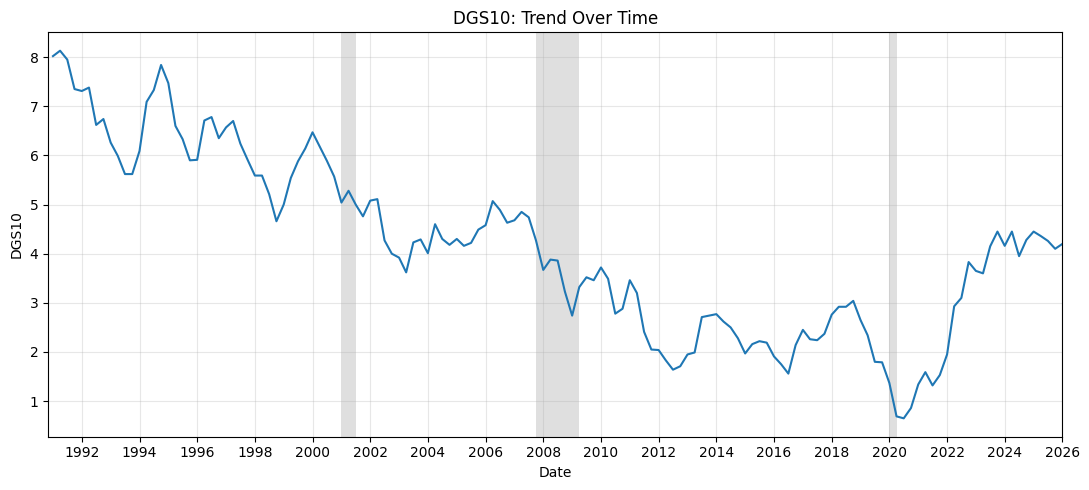

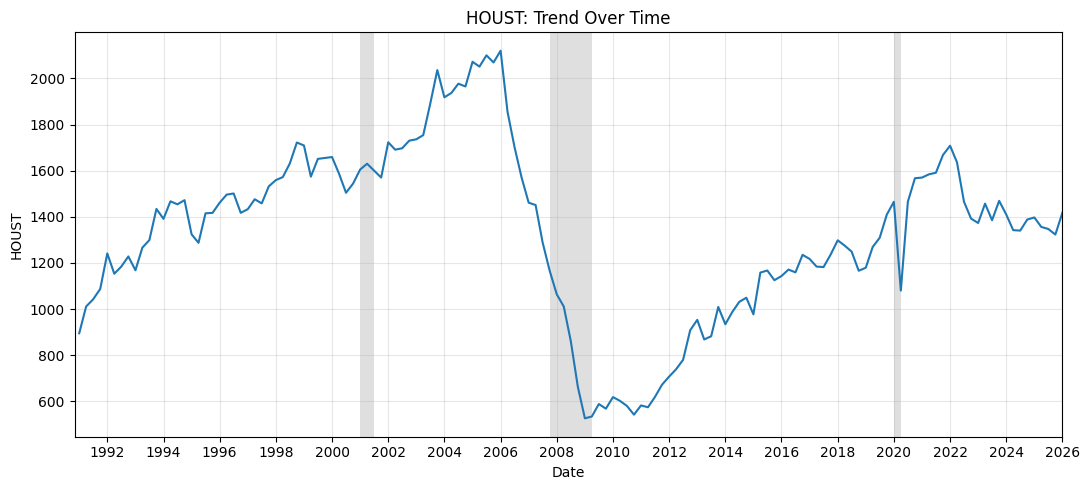

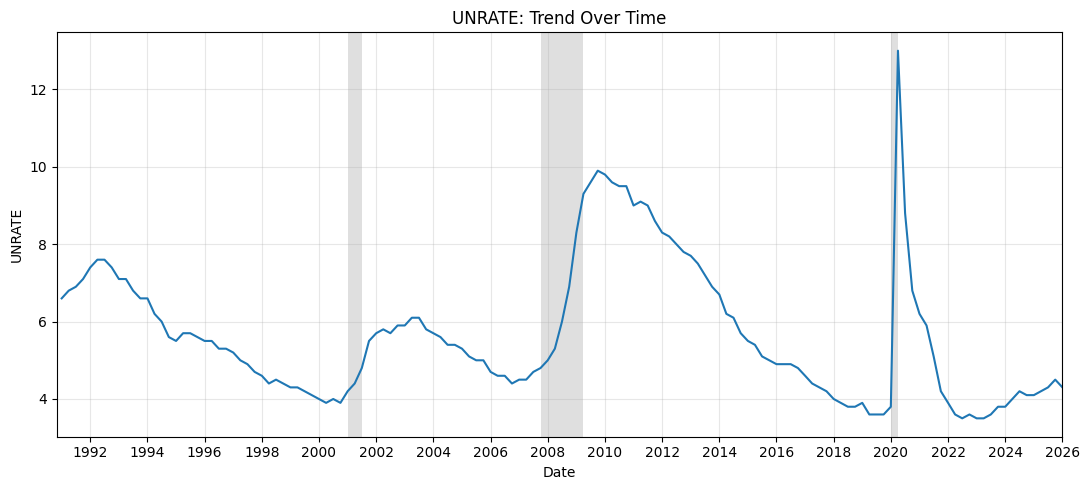

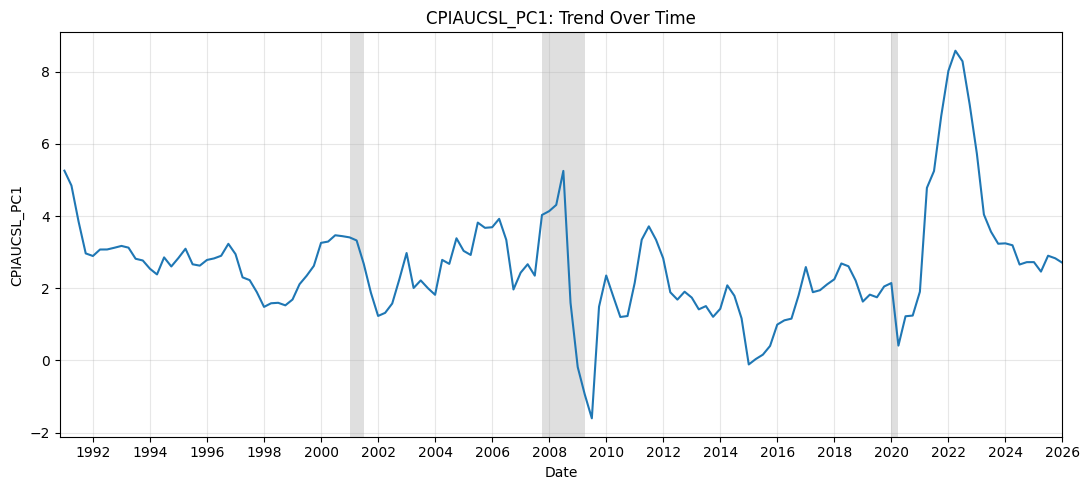

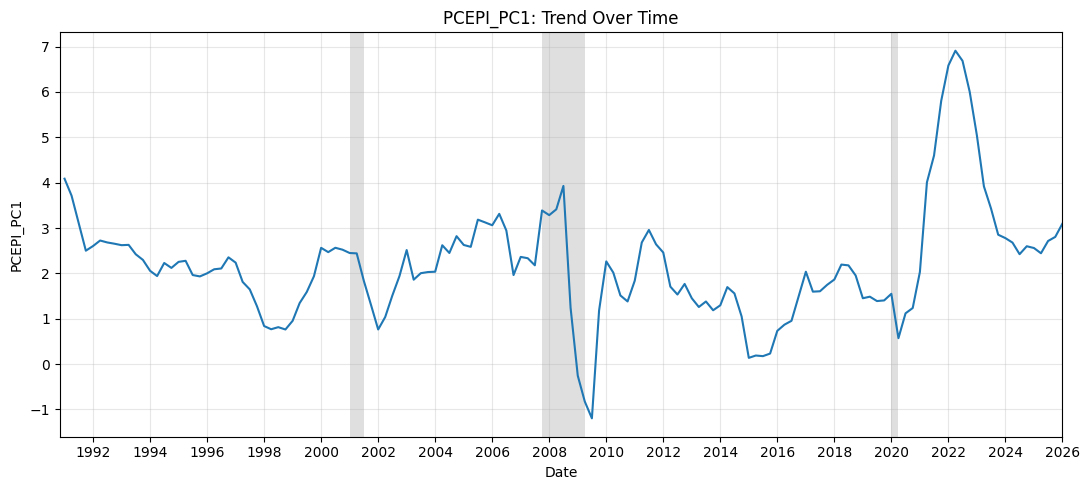

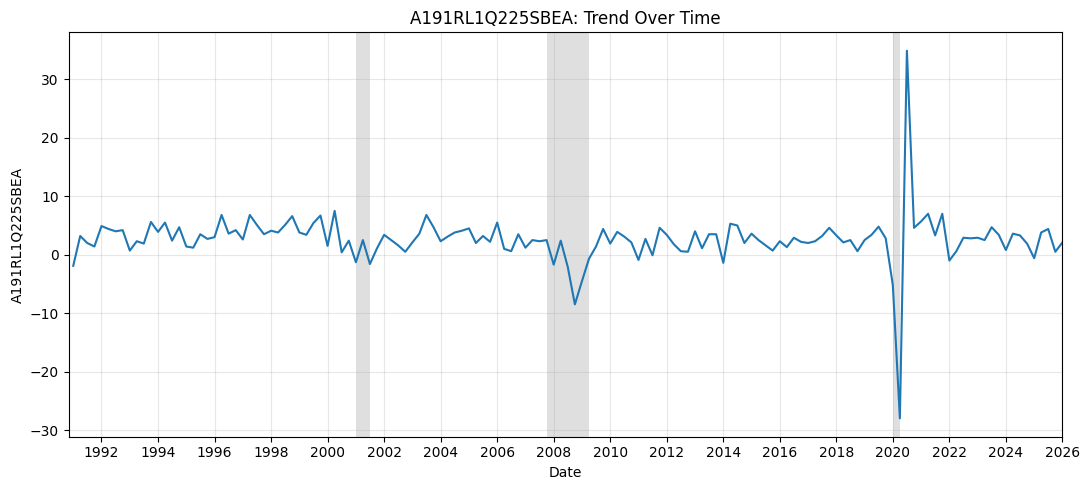

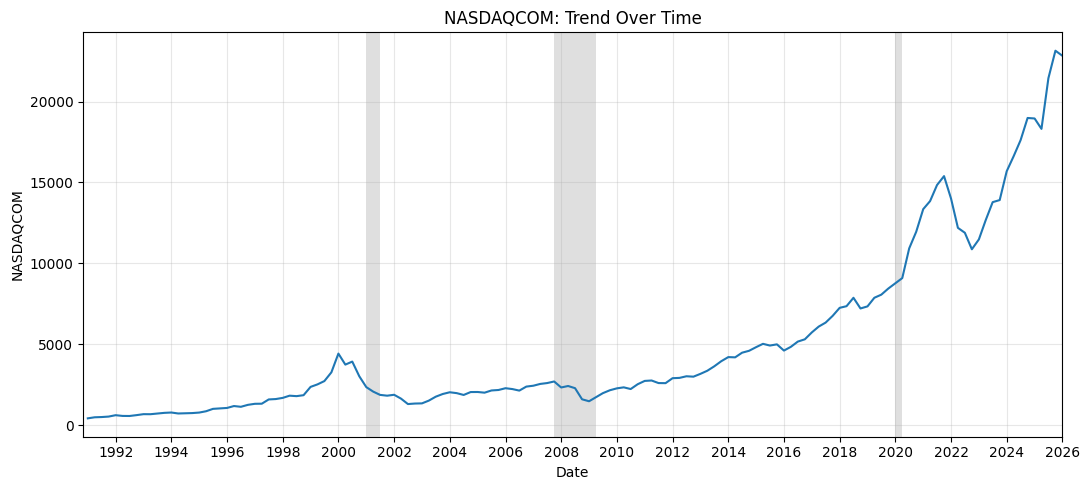

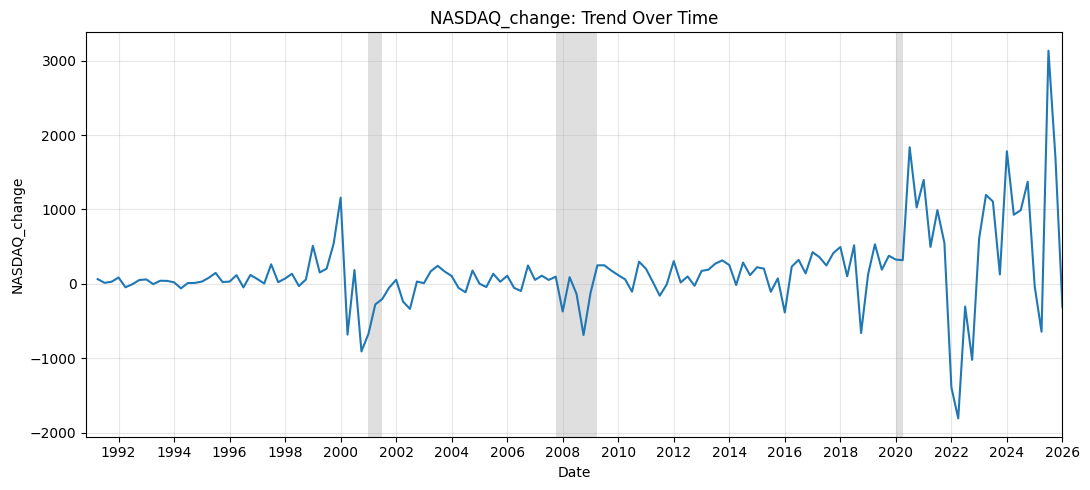

In [8]:
df["observation_date"] = pd.to_datetime(df["observation_date"])
for col in variables[1:len(variables)-1]:
    fig, ax = plt.subplots(figsize=(11, 5))

    ax.plot(df["observation_date"], df[col], linewidth=1.5)
    shade_recessions(ax, df)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    ax.set_xlim(
    pd.Timestamp("1990-11-01"),
    pd.Timestamp("2026-01-01")
    )
    
    ax.set_title(f"{col}: Trend Over Time")
    ax.set_xlabel("Date")
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    plt.show()
    plt.close(fig)

Going through the charts, I just want to point out some stuff that I find interesting.

In the first chart for credit card delinquency, usually the rate goes up during recessions. However during Covid, it actually went down which I would assume is because of the stimulus checks, which allowed them to have extra money to cover their debts.

The 10-year Treasury yield generally declined before 2020 before increasing during the subsequent recovery. The initial decline coincided with economic uncertainty and increased demand for safe assets during the COVID-19 pandemic. The subsequent increase occurred alongside rising inflation and monetary tightening. These changes provide context for the financial conditions surrounding credit-card delinquency, although the relationship between Treasury yields and delinquency rates is not necessarily causal.

The graph of new houses being built is interesting. There was a boom from 2004 to 2006. After it, the rate of new housing plummetted around 2 years before the Great Recession. After, it slowly returned to 1994-1996 levels.

For the unemployment rate, it follows the normal boom bust cycle where it rises quickly during and a little bit after recessions and then slowly comes down. However the Covid one looks like a spike where it just rapidly goes up and returns to pre-Covid levels in like 2 years. However, since 2023, it's started steadily slowly climbing up again

The change in CPI and change in PCE graphs resemble each other so I will be talking about them together. The prices do decrease during recessions and increase after. However the rate of price increases peaked in 2022 after Covid, probably due to the disrupted supply line among other factors.

The change of GDP is relatively flat, usually increasing at a rate between 0-10%. However, the COVID-19 pandemic produced an unprecedented disruption, with real GDP contracting sharply in early 2020 before rebounding substantially in the following quarter. These extreme fluctuations reflect the sudden economic shutdowns and subsequent reopening of businesses as economic activity resumed. GDP growth later returned to a more typical range. This pattern illustrates how the pandemic created an unusually severe, short-term economic shock compared with the fluctuations observed during most of the study period.

The NASDAQ Composite exhibited a long-term upward trend over the study period, although its growth was not uniform. From 1991 through much of the 2010s, the index experienced several periods of growth and decline, including the dot-com bubble and subsequent crash in the early 2000s. Its upward trend accelerated during the latter half of the 2010s and continued after the onset of the COVID-19 pandemic. Following a sharp decline in 2022, the index recovered and reached new highs by the end of 2025. The quarter-to-quarter changes also appear more volatile in the later years of the study period, suggesting that the size of its fluctuations increased alongside its overall growth. However, because the index is measured in points, larger absolute changes in later years may partly reflect its higher overall level rather than an increase in volatility relative to its size.

# Variables during Recession Comparison

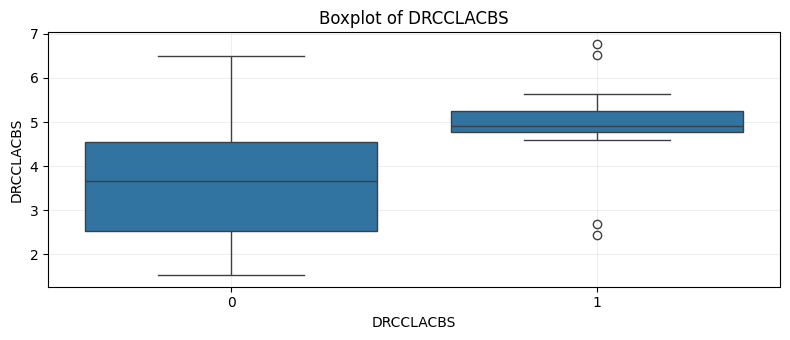

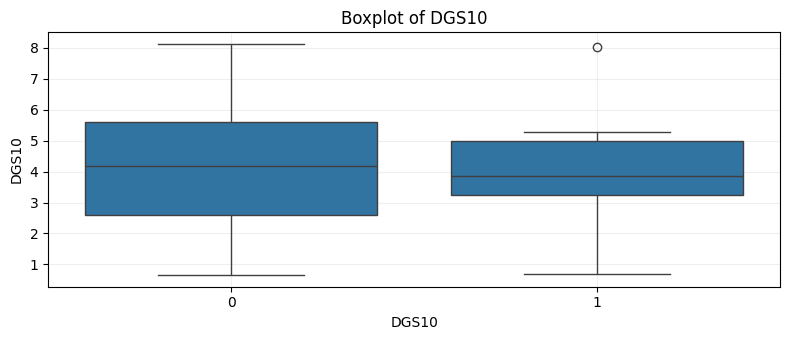

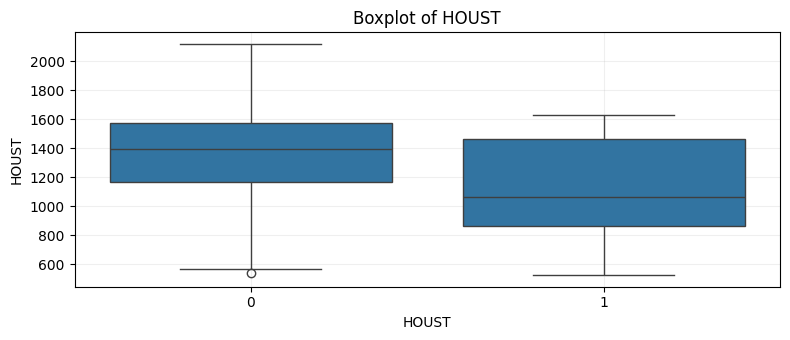

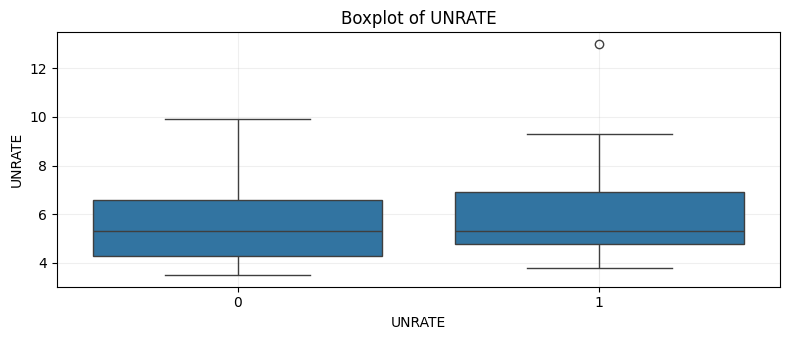

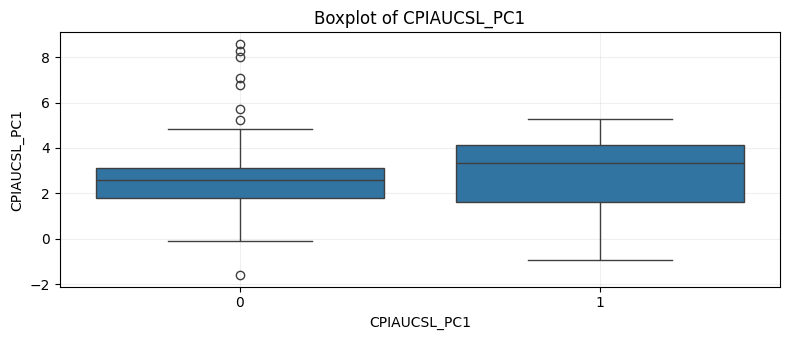

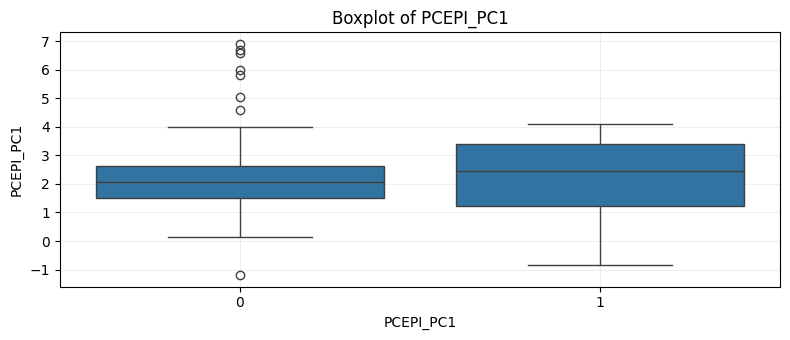

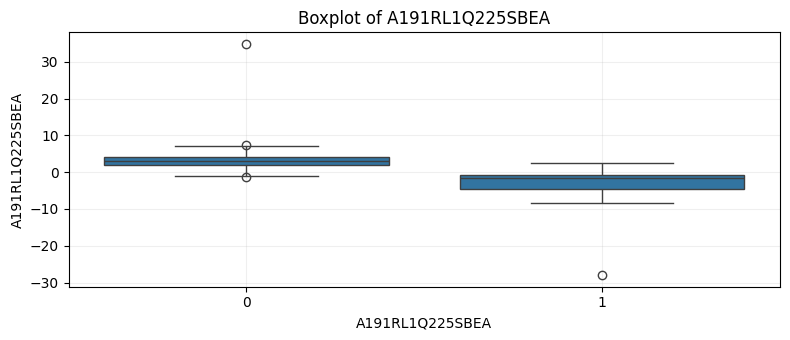

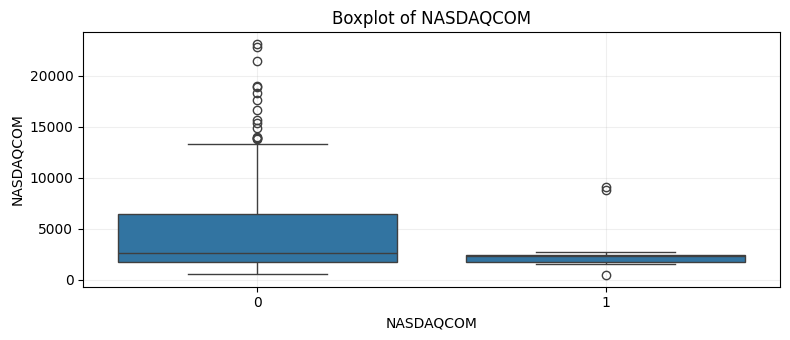

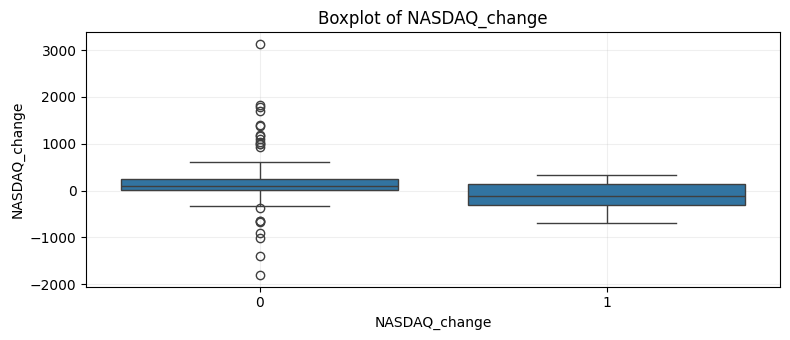

In [9]:
for col in variables[1:len(variables)-1]:
    values = df[col].dropna()

    if values.empty:
        continue

    fig, ax = plt.subplots(figsize=(8, 3.5))

    sns.boxplot(
    data=df,
    x="Recession",
    y=col
)

    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(col)
    ax.grid(True, alpha=0.2)

    fig.tight_layout()


Looking through these box plots, the most definitive results are that credit card delinquency rates do increase during recessions, the number of houses being built generally decreases, and GDP unsurprisingly decreases. The changes in the NASDAQ Composite are also slightly more negative than usual. 

CPI and PCE have a higher median during recession but a larger IQR and therefore I'm not going to conclude anything definitively.

I think the unemployment median is the exact same both during a recession and not during.

# Correlation and Scatterplots

<Axes: >

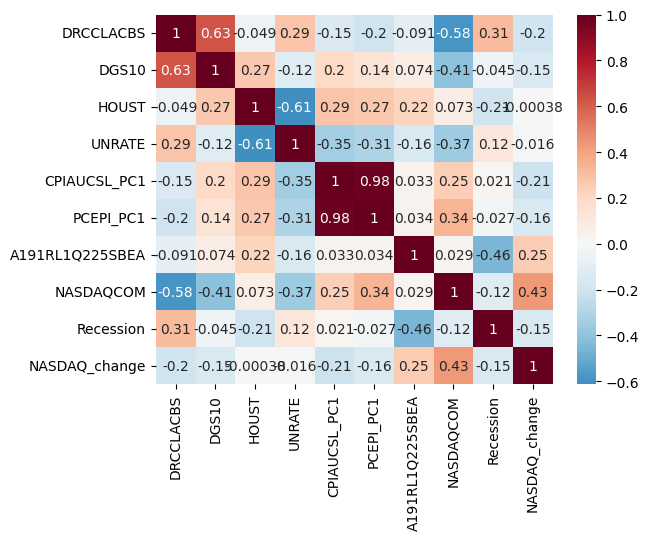

In [10]:
df_corr=df.drop(columns=["observation_date","NASDAQCOM_shift"])
correlation_matrix=df_corr.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="RdBu_r", center=0)

It seems like there's a strong positive correlation between delinquency rates and the market yield on Treasury bonds, moderate positive correlation between the rate and unemployment and recession, and a strong negative correlation with NASDAQ Composite.

The correlation with the changes in the composite are fairly weak interestingly enough.

Also the correlation between CPI and PCE are nearly one, so I will look at that as well.

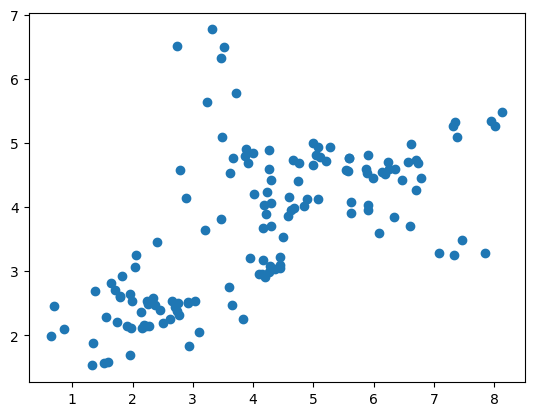

In [11]:
plt.scatter(x=df["DGS10"],y=df["DRCCLACBS"])

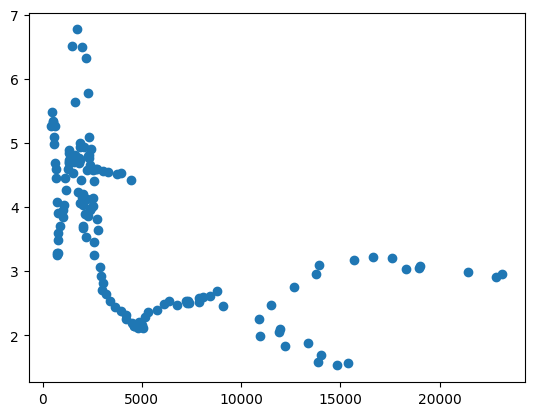

In [12]:
plt.scatter(x=df["NASDAQCOM"],y=df["DRCCLACBS"])

Because it looked asymptotic, I decided to check the log of the NASDAQ Composite to see if it would be more straight line-ish.

The correlation between the rates and the log of NASDAQ Composite is -0.69


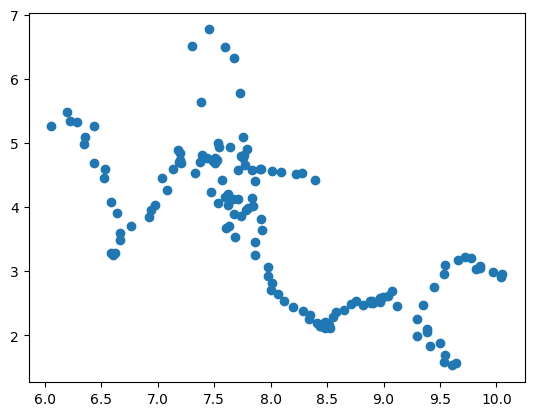

In [13]:
df["log_nasdaq"]=np.log(df["NASDAQCOM"])
print(f"The correlation between the rates and the log of NASDAQ Composite is {round(df["DRCCLACBS"].corr(df["log_nasdaq"]),2)}")
plt.scatter(x=df["log_nasdaq"],y=df["DRCCLACBS"])

Because it got more straight line-ish, I decided to make sure I wasn't missing anything with HOUST which is measured in the 1000s.

The correlation between the rates and the log of houses built is -0.13


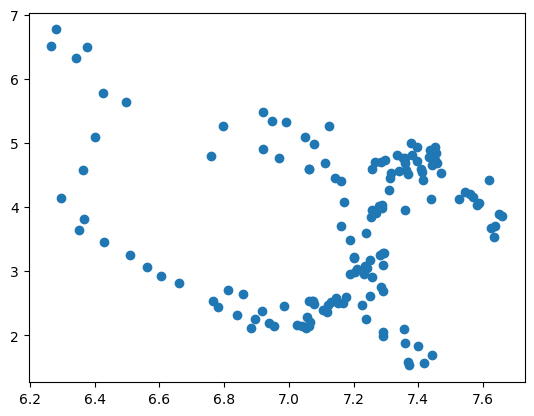

In [14]:
df["log_houst"]=np.log(df["HOUST"])
print(f"The correlation between the rates and the log of houses built is {round(df["DRCCLACBS"].corr(df["log_houst"]),2)}")
plt.scatter(x=df["log_houst"],y=df["DRCCLACBS"])

So it got relatively more negative, but still is pretty weak overall.

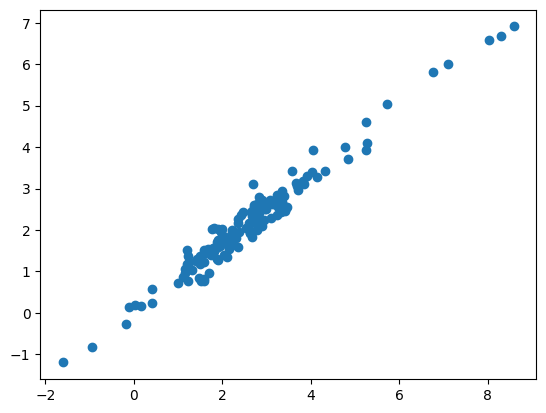

In [15]:
plt.scatter(x=df["CPIAUCSL_PC1"],y=df["PCEPI_PC1"])

This is just a straight line so they definitely have a relationship.

# Conclusion

This exploratory data analysis examined the relationship between credit-card delinquency rates and several economic indicators from 1991 through 2026. Overall, the findings suggest that delinquency rates are associated with broader economic conditions, particularly recessions, unemployment, Treasury yields, and stock-market performance.

The clearest pattern is that credit-card delinquency rates tend to increase during recessions, while housing construction and GDP growth generally decline. However, the COVID-19 recession differed from this pattern, as delinquency rates fell despite a sharp increase in unemployment. Government stimulus payments and other forms of financial assistance may help explain this divergence, although further analysis would be needed to establish their role. The correlation analysis also identified a positive relationship between delinquency rates and 10-year Treasury yields, as well as a moderate positive relationship with unemployment. Conversely, delinquency rates were negatively correlated with the NASDAQ Composite, including a correlation of approximately −0.69 with its logarithm. However, the relationship with quarterly changes in the NASDAQ was relatively weak, suggesting that its overall long-term trend may be more closely associated with delinquency rates than its short-term fluctuations.

The analysis also identified important limitations. Several economic indicators exhibit substantial changes over time, which can influence correlations and make it difficult to distinguish meaningful relationships from shared trends. Additionally, the strong relationship between CPI and PCE inflation measures indicates that these variables provide overlapping information. Comparisons between recessionary and non-recessionary periods also reveal that economic conditions do not always follow the same pattern, particularly during exceptional events such as the COVID-19 pandemic. Because this analysis is exploratory, the observed associations cannot establish that any individual indicator causes changes in credit-card delinquency.

In conclusion, credit-card delinquency appears to be related to the broader economic environment, with recessions and certain financial-market conditions providing useful context for understanding changes in household financial distress. Future research could build on these findings by examining lagged relationships, accounting for long-term trends, and using regression models to assess whether individual economic indicators remain associated with delinquency when other factors are considered. This could help clarify which indicators provide the most useful information for understanding and anticipating financial stress among consumers.

# Endnotes

Board of Governors of the Federal Reserve System (US), Delinquency Rate on Credit Card Loans, All Commercial Banks [DRCCLACBS], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/DRCCLACBS, October 9, 2026. 

Board of Governors of the Federal Reserve System (US), Market Yield on U.S. Treasury Securities at 10-Year Constant Maturity, Quoted on an Investment Basis [DGS10], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/DGS10, October 9, 2026. 

Hamilton, James, Dates of U.S. recessions as inferred by GDP-based recession indicator [JHDUSRGDPBR], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/JHDUSRGDPBR, October 9, 2026. 

Nasdaq, Inc., NASDAQ Composite [NASDAQCOM], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/NASDAQCOM, October 9, 2026. 

U.S. Bureau of Economic Analysis, Real Gross Domestic Product [A191RL1Q225SBEA], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/A191RL1Q225SBEA, October 9, 2026. 

U.S. Bureau of Labor Statistics, Consumer Price Index for All Urban Consumers: All Items in U.S. City Average [CPIAUCSL], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/CPIAUCSL, October 9, 2026. 

U.S. Bureau of Labor Statistics, Unemployment Rate [UNRATE], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/UNRATE, October 9, 2026. 

U.S. Census Bureau and U.S. Department of Housing and Urban Development, New Privately-Owned Housing Units Started: Total Units [HOUST], retrieved from FRED, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/HOUST, October 9, 2026. 

